# Лабораторная работа №2. Табличные данные и SQL

В этой работе мы познакомимся с двумя способами работы с табличными данными:

1. библиотекой **Pandas**, которая хранит таблицу в оперативной памяти в объекте `DataFrame`;
2. базой данных **SQLite**, к которой можно обращаться с помощью языка SQL.

В качестве данных используется табличная выборка из **CircuitNet-N14** для задачи прогнозирования загруженности трассировки. Каждая строка идентифицируется полем `cell_id` и содержит признаки одной выбранной позиции координатной сетки для конкретного варианта физического размещения.

Обозначения: ⭐ — простое задание; ⭐⭐ — задание на 2 балла; 💫 — конец задания.


## 0. Что описывают данные

**Интегральная схема** — электронная схема, реализованная на кристалле полупроводника. На этапе физического проектирования элементы схемы нужно разместить на кристалле и соединить проводниками в металлических слоях.

Простая интегральная схема состоит из:

- **стандартных элементов (STDCELL)** — простых элементов, например, логических вентилей, триггеров (регистров), счётчиков и т. п.;
- **ячеек ввода-вывода (I/O)** — элементов, через которые схема взаимодействует с внешним миром.

Упрощённый маршрут проектирования интегральной схемы выглядит следующим образом:

| Этап | Задача |
|---|---|
| RTL-проектирование | Описание цифровой схемы на Verilog/SystemVerilog/VHDL на уровне передачи между регистрами |
| Логический синтез (Logic synthesis) | Преобразование RTL в нетлист (список соединений), состояющий из стандартных логических элементов выбранной технологии и соединений (цепей), связывающих их. |
| Планировка (Floorplanning) | Определение размеров кристалла, размещение крупных блоков, памяти и I/O |
| PDN | Размещение шин питания |
| Размещение (Placement) | Физическое размещение стандартных элементов на кристалле |
| Синтез тактовых цепей (Clock tree synthesis) | Синтез тактовых цепей, расстановка буферов и инверторов для равномерного распределения тактового сигнала по регистрам схемы с минимальной задержкой |
| Трассировка (Routing) | Соединение размещённых элементов металлическими проводниками |

В данной лабораторной работе рассматриваются данные, связанные с этапами размещения и трассировки.

Этап трассировки делится на глобальной `(GR)` и детальной (`DR`) трассировки.

На этапе глобальной трассировки площадь кристалла разбивается на множество прямоугольных ячеек (областей) равномерной сеткой и затем на данной сетке выполняется поиск пути между элементами.

На этапе детальной трассировки непосредственно строятся физические соединения.

Каждая область имеет уникальный идентификатор `cell_id`.

Для одной исходной схемы могут существовать разные варианты размещения. В таблице каждый из вариантов имеет свой уникальный идентификатор `sample_id`.


Ниже приведены упрощённые иллюстрации процесса трассировки. Первая показывает поиск маршрута по дискретной сетке при глобальной трассировке, а вторая — представление полученного маршрута в виде областей прохождения соединения между блоками схемы.

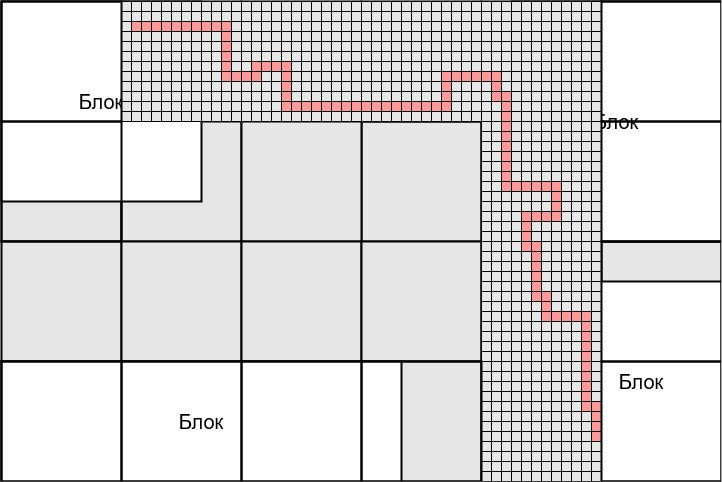

*Упрощённый пример глобальной трассировки по координатной сетке.*

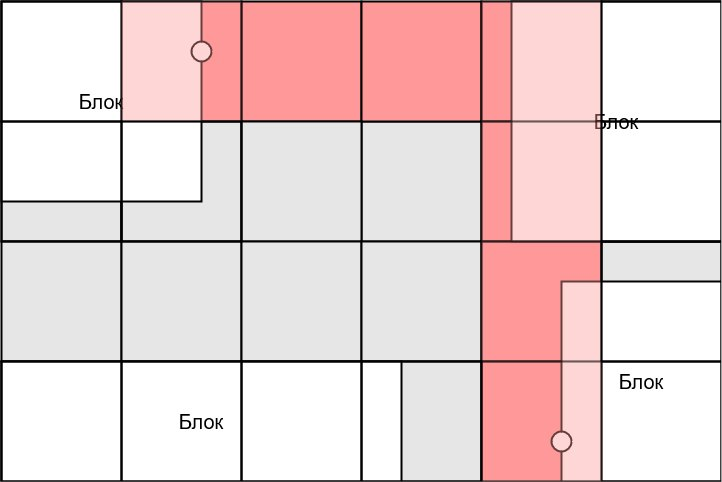

*Упрощённое представление маршрута и областей прохождения соединения между блоками.*

### Спрос на трассировку и загруженность маршрутизации

Для каждой области `cell_id` доступны ограниченные ресурсы для построения соединений между элементами схемы.

- **Спрос на трассировку** показывает, насколько много соединений предположительно потребуется провести через выбранную область.
- **Загруженность маршрутизации** (`congestion`) - нормированная сумма горизонтальной и вертикальной перегруженности после глобальной трассировки. Чем больше значение, тем сильнее дефицит ресурсов трассировки.
- **RUDY** (`Rectangular Uniform wire DensitY`) — численная оценка спроса на трассировку, построенная по предполагаемым соединениям и их геометрии.
- `rudy_pin` — вариант признака RUDY, который дополнительно учитывает **контакты (pins)** элементов, то есть точки соединения проводников.

Признаки `macro_region`, `rudy`, `rudy_pin` и `congestion` независимо нормированы в диапазон от 0 до 1 внутри каждого `sample_id`. Поэтому в работе сравниваются прежде всего относительные значения; абсолютные уровни разных `sample_id` следует сопоставлять с осторожностью.


## 1. DataFrame

Файл `data/circuitnet_cells.csv` содержит 56 000 строк: 140 вариантов (`sample_id`) по 400 выбранных координат. Полная карта каждого варианта имеет размер 256×256, но в табличный экспорт входит только выборка позиций. Каждая строка имеет уникальный `cell_id`.

Ниже приведены столбцы, которые будут встречаться в работе.

| Столбец | Смысл |
|---|---|
| `cell_id` | глобально уникальный идентификатор строки экспорта |
| `sample_id` | уникальный идентификатор варианта схемы |
| `split` | часть набора данных: `train` или `test` |
| `design` | имя исходной схемы, для которой построен вариант размещения |
| `frequency` | заданная тактовая частота в МГц |
| `macro_placement` | номер варианта размещения макроблоков |
| `floorplan_utilization` | заданная плотность заполнения площади кристалла в процентах |
| `floorplan_aspect_ratio` | заданное отношение сторон кристалла |
| `power_density` | номер настройки сетки питания (Power Mesh Setting); не означает физическую плотность мощности |
| `flow_variant` | этап, когда вставляются филлеры: `ap` — после размещения, `ar` — после трассировки |
| `row`, `col` | координаты области в представлении 256×256 |
| `macro_region` | нормированный признак присутствия макроблока для данного `cell_id` |
| `rudy` | нормированная оценка спроса на трассировку |
| `rudy_pin` | нормированная оценка спроса на трассировку с учётом контактов элементов |
| `congestion` | нормированная сумма горизонтальной и вертикальной перегруженности глобальной трассировки |

`split` принимает значения `train` и `test`. В этой лабораторной мы **не обучаем модель**: это готовое разбиение набора данных на две части для сравнения. Здесь `train` содержит `design == 'nvdla-small'`, а `test` — `design == 'openc910-1'`, поэтому различия распределений могут быть связаны с самими схемами.


### 1.1. Загрузка таблицы и первые сведения о Pandas

`pandas` — библиотека Python для работы с табличными данными. Основной класс библиотеки называется `DataFrame`: его удобно представлять как таблицу со строками и столбцами.

Для чтения CSV-файла используется функция `pd.read_csv(...)`.

Также импортируем:

- `Path` — для аккуратной работы с путями к файлам;
- `matplotlib.pyplot` — базовые средства построения графиков;
- `seaborn` — библиотеку визуализации поверх Matplotlib, которая упрощает построение статистических графиков.


In [7]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path('data')
csv_path = DATA_DIR / 'circuitnet_cells.csv'
db_path = DATA_DIR / 'circuitnet.sqlite'

Считаем CSV-файл. Результатом будет объект `DataFrame`.

Метод `head()` показывает первые пять строк и позволяет быстро проверить, что данные прочитались корректно.


In [8]:
cells = pd.read_csv(csv_path)
cells.head()

,cell_id,sample_id,split,design,frequency,macro_placement,floorplan_utilization,floorplan_aspect_ratio,power_density,flow_variant,row,col,macro_region,rudy,rudy_pin,congestion
0,1,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,207,165,0.145591,0.085855,0.073132,0.120035
1,2,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,114,53,0.845231,0.081959,0.076143,0.119627
2,3,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,171,128,0.845591,0.036368,0.076134,0.119627
3,4,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,111,172,0.145591,0.234799,0.122166,0.117688
4,5,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,78,29,0.848364,0.210342,0.075623,0.119627


Проверим тип объекта и размер таблицы.

- `cells.__class__` показывает класс объекта;
- `cells.shape` возвращает кортеж `(число_строк, число_столбцов)`.

Для этого набора ожидается 56 000 строк и 16 столбцов.


In [9]:
cells.__class__, cells.shape

(pandas.DataFrame, (56000, 16))

### 1.2. Выбор столбцов и строк

Один столбец выбирается по его имени:

```python
cells['congestion']
```

Результат имеет тип `Series` — одномерная структура Pandas.

Если нужно выбрать несколько столбцов, передаётся **список имён**:

```python
cells[['sample_id', 'congestion']]
```

Результат уже является новым `DataFrame`.


In [10]:
cells['congestion'].head()

0    0.120035
1    0.119627
2    0.119627
3    0.117688
4    0.119627
Name: congestion, dtype: float64

Теперь выберем несколько столбцов. Двойные квадратные скобки появляются потому, что внутри `cells[...]` передаётся обычный Python-список с именами столбцов.


In [11]:
cells[['sample_id', 'row', 'col', 'rudy', 'congestion']].head()

,sample_id,row,col,rudy,congestion
0,train_case_001,207,165,0.085855,0.120035
1,train_case_001,114,53,0.081959,0.119627
2,train_case_001,171,128,0.036368,0.119627
3,train_case_001,111,172,0.234799,0.117688
4,train_case_001,78,29,0.210342,0.119627


У `DataFrame` есть индекс — метки строк. Сразу после чтения CSV Pandas создаёт индекс `0, 1, 2, ...`.

В нашей таблице уже есть уникальное поле `cell_id`, поэтому удобно сделать его индексом с помощью `set_index`.

Метод `.loc[...]` выбирает строки **по меткам индекса**. Метод `.iloc[...]` выбирает строки **по порядковым номерам**.


In [12]:
cells = cells.set_index('cell_id')
cells.loc[1]

sample_id                 train_case_001
split                              train
design                       nvdla-small
frequency                            200
macro_placement                        2
floorplan_utilization                 65
floorplan_aspect_ratio               1.0
power_density                          2
flow_variant                          ar
row                                  207
col                                  165
macro_region                    0.145591
rudy                            0.085855
rudy_pin                        0.073132
congestion                      0.120035
Name: 1, dtype: object

С помощью `.loc` можно одновременно выбрать диапазон строк и нужные столбцы.

В записи ниже:

- `10:20` — метки строк от 10 до 20 включительно;
- список после запятой — столбцы, которые нужно оставить.


In [13]:
cells.loc[10:20, ['design', 'row', 'col', 'congestion']]

,design,row,col,congestion
cell_id,,,,
10,nvdla-small,111,91,0.119627
11,nvdla-small,253,34,0.119626
12,nvdla-small,75,78,0.119627
13,nvdla-small,44,192,0.119627
14,nvdla-small,210,180,0.119561
15,nvdla-small,110,196,0.118100
16,nvdla-small,5,168,0.119627
17,nvdla-small,72,188,0.119627
18,nvdla-small,228,74,0.122097


### 1.3. Фильтрация по условию

Сравнение столбца с числом выполняется для каждой строки отдельно.

Например,

```python
cells['congestion'] > 0.2
```

создаёт `Series` из значений `True` и `False`. Такая последовательность называется **булевой маской**.

Если передать маску в `cells[...]`, останутся только строки, для которых условие истинно.


In [14]:
high_load = cells['congestion'] > 0.2
high_load.value_counts()

congestion
False    53450
True      2550
Name: count, dtype: int64

Используем полученную булеву маску как фильтр.


In [15]:
cells[high_load].head()

,sample_id,split,design,frequency,macro_placement,floorplan_utilization,floorplan_aspect_ratio,power_density,flow_variant,row,col,macro_region,rudy,rudy_pin,congestion
cell_id,,,,,,,,,,,,,,,
31,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,229,200,0.145591,0.162301,0.120072,0.344561
55,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,188,130,0.145591,0.115184,0.248998,0.479989
68,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,125,102,0.145591,0.251050,0.429416,0.330799
125,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,70,132,0.145253,0.191288,0.163382,0.232322
144,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,70,161,0.145591,0.165217,0.263087,0.201873


Несколько условий можно объединять.

В Pandas:

- `&` означает логическое «И»;
- `|` означает логическое «ИЛИ»;
- каждое отдельное сравнение нужно заключать в круглые скобки.

Ниже оставим только строки из части `train`, у которых `rudy > 0.5`.


In [16]:
train_high_rudy = cells[
    (cells['split'] == 'train') &
    (cells['rudy'] > 0.5)
]

train_high_rudy.head()

,sample_id,split,design,frequency,macro_placement,floorplan_utilization,floorplan_aspect_ratio,power_density,flow_variant,row,col,macro_region,rudy,rudy_pin,congestion
cell_id,,,,,,,,,,,,,,,
167,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,196,213,0.145591,0.572696,0.124851,0.119624
236,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,198,200,0.145591,0.504921,0.202764,0.119627
388,train_case_001,train,nvdla-small,200,2,65,1.0,2,ar,120,47,0.844738,0.691774,0.125048,0.119627
438,train_case_002,train,nvdla-small,500,1,65,1.0,4,ar,236,125,0.022863,0.504760,0.110911,0.170024
492,train_case_002,train,nvdla-small,500,1,65,1.0,4,ar,55,216,0.088689,0.538060,0.133245,0.179101


### Задание 1. Фильтрация и пропуски — 2 балла ⭐⭐

1. Вычислите **количество `cell_id`**, у которых `congestion` выше каждого из значений `0.1`, `0.2`, `0.5`.
2. Для каждого из этих порогов вычислите **долю** таких `cell_id` от общего числа строк таблицы.
3. Повторите пункты 1–2 отдельно:
   - для строк со `split == 'train'`;
   - для строк со `split == 'test'`.
4. Отдельно укажите, сколько строк имеют пропущенное значение `congestion`.

Долю можно получить как среднее значение булевой маски: в Python `True` при вычислениях эквивалентен `1`, а `False` — `0`.


In [26]:
n1 = (cells['congestion'] > 0.1).value_counts()[True]
n2 = (cells['congestion'] > 0.2).value_counts()[True]
n3 = (cells['congestion'] > 0.5).value_counts()[True]

n = cells.shape[0]

d1 = n1 / n
d2 = n2 / n
d3 = n3 / n

print(f'Congestion > 0.1: {n1} ({d1:.2%})')
print(f'Congestion > 0.2: {n2} ({d2:.2%})')
print(f'Congestion > 0.5: {n3} ({d3:.2%})')

t1 = ((cells['split'] == 'train') & (cells['congestion'] > 0.1)).value_counts()[True]
t2 = ((cells['split'] == 'train') & (cells['congestion'] > 0.2)).value_counts()[True]
t3 = ((cells['split'] == 'train') & (cells['congestion'] > 0.5)).value_counts()[True]

d1 = t1 / n
d2 = t2 / n
d3 = t3 / n

print(f'Train, Congestion > 0.1: {t1} ({d1:.2%})')
print(f'Train, Congestion > 0.2: {t2} ({d2:.2%})')
print(f'Train, Congestion > 0.5: {t3} ({d3:.2%})')

t1 = ((cells['split'] == 'test') & (cells['congestion'] > 0.1)).value_counts()[True]
t2 = ((cells['split'] == 'test') & (cells['congestion'] > 0.2)).value_counts()[True]
t3 = ((cells['split'] == 'test') & (cells['congestion'] > 0.5)).value_counts()[True]

d1 = t1 / n
d2 = t2 / n
d3 = t3 / n

print(f'Test, Congestion > 0.1: {t1} ({d1:.2%})')
print(f'Test, Congestion > 0.2: {t2} ({d2:.2%})')
print(f'Test, Congestion > 0.5: {t3} ({d3:.2%})')

print(f'No Congestion: {(cells["congestion"] == 0.0).value_counts()[True]}')

Congestion > 0.1: 34688 (61.94%)
Congestion > 0.2: 2550 (4.55%)
Congestion > 0.5: 54 (0.10%)
Train, Congestion > 0.1: 25218 (45.03%)
Train, Congestion > 0.2: 1881 (3.36%)
Train, Congestion > 0.5: 13 (0.02%)
Test, Congestion > 0.1: 9470 (16.91%)
Test, Congestion > 0.2: 669 (1.19%)
Test, Congestion > 0.5: 41 (0.07%)
No Congestion: 2


### 1.4. Статистики и агрегирование

Для вычисления простых статистических характеристик у `Series` и `DataFrame` есть готовые методы:

- `.min()` — минимальное значение;
- `.max()` — максимальное значение;
- `.mean()` — среднее арифметическое;
- `.median()` — медиана;
- `.std()` — стандартное отклонение.

Сначала применим их к одному столбцу `congestion`.


In [27]:
min_congestion = cells['congestion'].min()
max_congestion = cells['congestion'].max()
mean_congestion = cells['congestion'].mean()
median_congestion = cells['congestion'].median()
std_congestion = cells['congestion'].std()

min_congestion, max_congestion, mean_congestion, median_congestion, std_congestion

(np.float64(0.0),
 np.float64(1.0),
 np.float64(0.12112426602322843),
 np.float64(0.11260033771395683),
 np.float64(0.045902747430683684))

Если нужно посчитать сразу несколько статистик для одного столбца, используется метод `.agg(...)` — сокращение от *aggregate* («агрегировать»).

В список передаются названия нужных операций. Следующий код делает то же самое, что несколько отдельных вызовов выше, но компактнее.


In [28]:
cells['congestion'].agg(['min', 'max', 'mean', 'median', 'std'])

min       0.000000
max       1.000000
mean      0.121124
median    0.112600
std       0.045903
Name: congestion, dtype: float64

### Группировка с `groupby`

`groupby` используется, когда статистики нужно посчитать **отдельно для нескольких групп строк**.

Например, `cells.groupby('design')` делит таблицу на группы по значению столбца `design`. Здесь `design` — имя исходной схемы, а не отдельный вариант её размещения.

После группировки можно выбрать столбец `congestion` и применить к каждой группе несколько агрегирующих функций.


In [29]:
design_stats = (
    cells
    .groupby('design')['congestion']
    .agg(['count', 'mean', 'std', 'max'])
)

design_stats

,count,mean,std,max
design,,,,
nvdla-small,33600,0.131824,0.043145,1.000000
openc910-1,22400,0.105075,0.045234,0.824317


Группировать можно сразу по нескольким столбцам.

В следующем примере каждая группа соответствует одному варианту размещения (`sample_id`). Вместе с `sample_id` оставляем `split` и `design`, чтобы они были видны в итоговой таблице.

Параметр `as_index=False` просит Pandas сохранить поля группировки обычными столбцами, а не превращать их в индекс.

В `.agg(...)` используется запись

```python
новое_имя=('исходный_столбец', 'операция')
```

Например, `mean_rudy=('rudy', 'mean')` создаёт новый столбец `mean_rudy`, равный среднему `rudy` внутри каждой группы.


In [30]:
sample_summary = (
    cells
    .groupby(['sample_id', 'split', 'design'], as_index=False)
    .agg(
        mean_rudy=('rudy', 'mean'),
        mean_rudy_pin=('rudy_pin', 'mean'),
        mean_congestion=('congestion', 'mean'),
        max_congestion=('congestion', 'max')
    )
)

sample_summary.head()

,sample_id,split,design,mean_rudy,mean_rudy_pin,mean_congestion,max_congestion
0,test_case_001,test,openc910-1,0.302351,0.179155,0.122588,0.443296
1,test_case_002,test,openc910-1,0.285099,0.152808,0.120384,0.372492
2,test_case_003,test,openc910-1,0.311335,0.149134,0.129715,0.543149
3,test_case_004,test,openc910-1,0.341960,0.162184,0.100826,0.504976
4,test_case_005,test,openc910-1,0.309034,0.118124,0.132184,0.421129


### Задание 2. Групповая статистика — 1 балл ⭐

Сгруппируйте строки по `frequency` и `floorplan_utilization`.

Для каждой комбинации этих двух параметров вычислите:

1. число `cell_id`;
2. среднее значение `rudy`;
3. среднее значение `congestion`;
4. 95-й процентиль `congestion` с помощью метода `.quantile(0.95)`.

Отсортируйте итоговую таблицу по убыванию **среднего `congestion`**.


In [32]:
stats = (
    cells
    .reset_index()
    .groupby(['frequency', 'floorplan_utilization'], as_index=False)
    .agg(
        count=('cell_id', 'count'),
        mean_rudy=('rudy', 'mean'),
        mean_congestion=('congestion', 'mean'),
        quantile_95_congestion=('congestion', lambda x: x.quantile(0.95))
    )
    .sort_values(by='mean_congestion', ascending=False)
)

stats

,frequency,floorplan_utilization,count,mean_rudy,mean_congestion,quantile_95_congestion
4,500,50,4800,0.136412,0.146555,0.188828
6,500,60,7200,0.219469,0.139107,0.222228
7,500,65,7200,0.224770,0.130754,0.179101
1,200,55,7200,0.222743,0.116721,0.185568
5,500,55,7200,0.202054,0.115549,0.163105
0,200,50,6800,0.242019,0.113557,0.187950
3,200,65,7200,0.216623,0.111296,0.150348
2,200,60,8400,0.209170,0.106028,0.151581


### 1.5. Графики

График помогает увидеть закономерности, которые трудно заметить в большой таблице.

В Python для этой работы часто используются три уровня инструментов:

- **Matplotlib** — базовая библиотека построения графиков;
- **Pandas `.plot`** — короткий способ построить график непосредственно из `Series` или `DataFrame`; внутри используется Matplotlib;
- **Seaborn** — библиотека поверх Matplotlib, которая удобна для статистических графиков и работы с категориями.

Ниже разберём два типа графиков.

#### Гистограмма

Гистограмма показывает распределение одного числового признака. Диапазон значений разбивается на интервалы (`bins`), после чего считается, сколько наблюдений попало в каждый интервал.


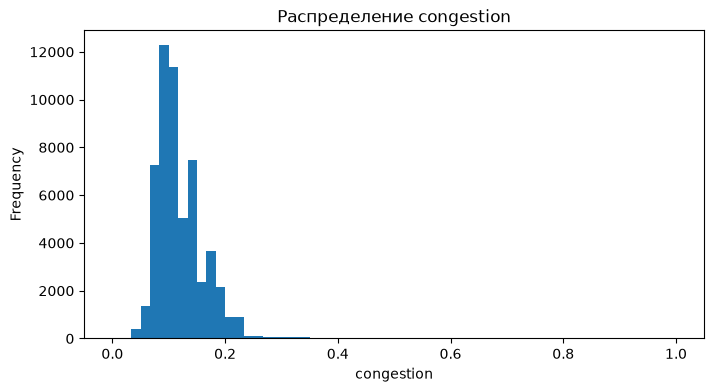

In [33]:
ax = cells['congestion'].plot.hist(
    bins=60,
    figsize=(8, 4),
    title='Распределение congestion'
)

ax.set_xlabel('congestion')

plt.show()

Seaborn особенно удобен, когда нужно сравнить распределения нескольких категорий. Например, параметр `hue='split'` автоматически разделяет наблюдения на `train` и `test` и добавляет легенду.

Ниже приведён учебный пример. Он использует всю таблицу, потому что гистограмма агрегирует множество наблюдений в ограниченное число интервалов.


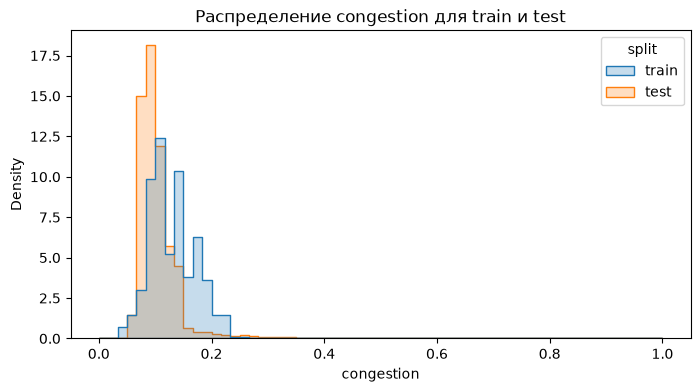

In [34]:
plt.figure(figsize=(8, 4))

sns.histplot(
    data=cells,
    x='congestion',
    hue='split',
    bins=60,
    stat='density',
    common_norm=False,
    element='step'
)

plt.title('Распределение congestion для train и test')
plt.show()

#### Диаграмма рассеяния (`scatter plot`)

Диаграмма рассеяния показывает связь двух числовых признаков: каждая строка таблицы становится одной точкой.

Если построить сразу десятки тысяч точек, они будут накладываться друг на друга. Поэтому для такого графика разумно взять случайную подвыборку.

Метод `.sample(5000, random_state=42)` выбирает 5000 случайных строк. `random_state=42` фиксирует генератор случайных чисел, поэтому при повторном запуске будут выбраны те же строки. Параметр `alpha < 1` делает точки полупрозрачными и уменьшает проблему наложения.


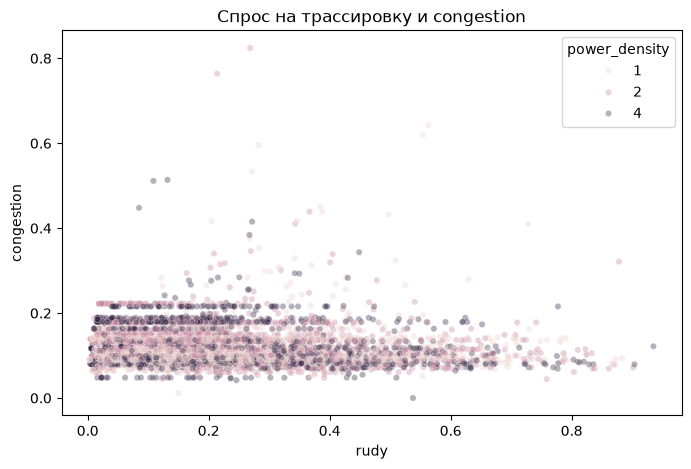

In [35]:
plot_sample = cells.sample(5000, random_state=42)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_sample,
    x='rudy',
    y='congestion',
    hue='power_density',
    alpha=0.35,
    s=20
)

plt.title('Спрос на трассировку и congestion')
plt.show()

### Задание 3. Визуализация — 2 балла ⭐⭐

Постройте три графика.

1. **Сравнение распределений** `congestion` для `train` и `test` по полной таблице. Подойдёт гистограмма или другой график распределения с разбиением по `split`.
2. **Диаграмму рассеяния** зависимости `congestion` от `rudy_pin`. Используйте случайную подвыборку не более 8 000 строк, `random_state=42` и прозрачность `alpha < 1`.
3. **График среднего `congestion`** для каждого значения `floorplan_utilization`. Сначала посчитайте среднее с помощью `groupby`, затем постройте график.

После графиков сформулируйте не менее трёх конкретных наблюдений, которые видны на визуализациях.

При сравнении `train` и `test` помните: эти части содержат разные значения `design`. В этой работе `design` означает имя исходной схемы; разные `sample_id` — это варианты размещения такой схемы. Поэтому отличие `train` от `test` не следует автоматически трактовать как эффект самого разбиения.


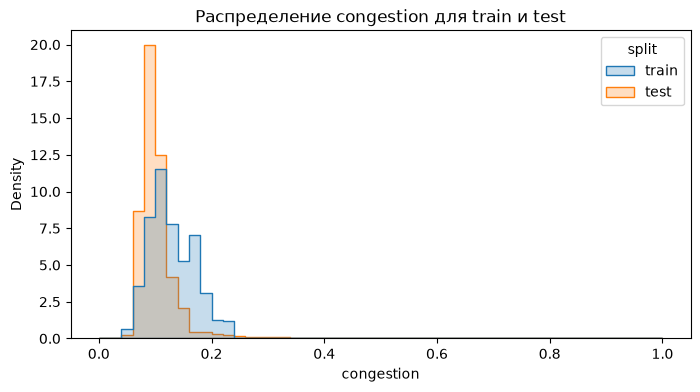

In [38]:
plt.figure(figsize=(8, 4))

sns.histplot(
    data=cells,
    x='congestion',
    hue='split',
    bins=50,
    stat='density',
    common_norm=False,
    element='step'
)

plt.title('Распределение congestion для train и test')
plt.show()


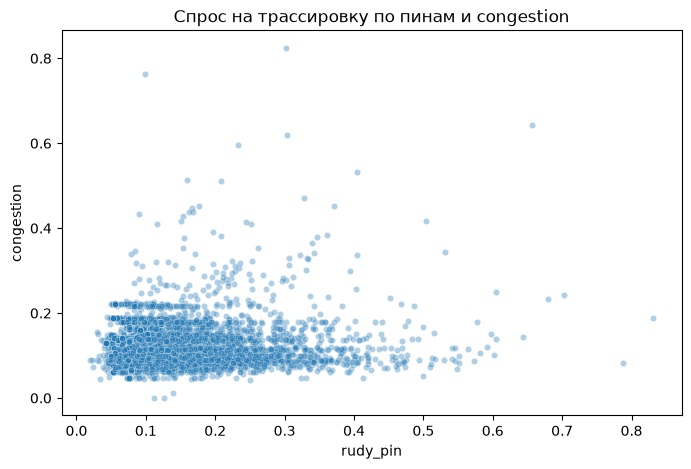

In [40]:
plot_sample = cells.sample(8000, random_state=42)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_sample,
    x='rudy_pin',
    y='congestion',
    alpha=0.35,
    s=20
)

plt.title('Спрос на трассировку по пинам и congestion')
plt.show()

,floorplan_utilization,congestion
0,50,0.127211
1,55,0.116135
2,60,0.121295
3,65,0.121025


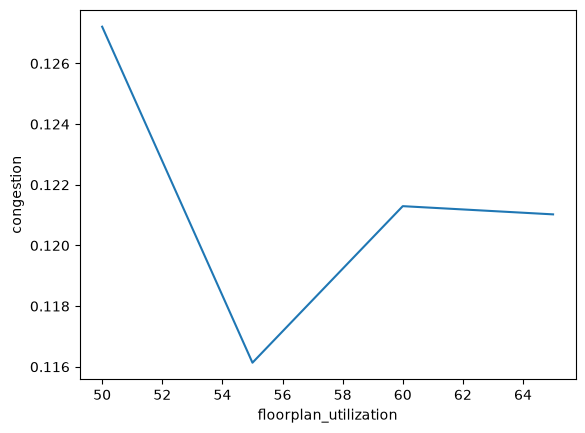

In [47]:
mean_congestion_by_utilization = (
    cells
    .groupby('floorplan_utilization')['congestion']
    .mean()
    .reset_index()
)

sns.lineplot(
    data=mean_congestion_by_utilization,
    x='floorplan_utilization',
    y='congestion'
)

mean_congestion_by_utilization

**Наблюдения по графикам:**

1. Видно, что плотности распределений при различных кофигурациях интегральной схемы обе примерно подчиняются нормальному распределению и их математические ожидания находятся близко друг к другу.
2. Облако довольно кучное в начальных значениях, но с ростом `rudy_pin` `congestion` продолжает концентрироваться у начальных показателей, также растёт число промахов.
3. Абсолютный максимум `mean_congestion` достигается при минимальной `floorplan_utilization`, абсолютный минимум `mean_congestion` достигается при `floorplan_utilization = 55`, далее `mean_congestion` слабо зависит от `floorplan_utilization`

## 2. SQLite и SQL

В первой части вся таблица была загружена в `DataFrame`. Теперь те же данные будем получать из базы SQLite.

**База данных** хранит данные в таблицах на диске. Язык **SQL** (`Structured Query Language`) позволяет описать, какие строки и столбцы нужно получить, отфильтровать или агрегировать.

SQLite — компактная СУБД, которая хранит базу в одном файле. В Python работа с SQLite доступна через встроенный модуль `sqlite3`.

Нам понадобятся два объекта:

- `Connection` — соединение с файлом базы данных;
- `Cursor` — объект, через который выполняются SQL-команды и читается результат запроса.


### 2.1. Структура базы данных

База `circuitnet.sqlite` хранит данные в двух связанных таблицах.

- `samples` — одна строка на вариант размещения (`sample_id`) и его параметры;
- `grid_cells` — одна строка на `cell_id` и его числовые характеристики.

Поле `sample_id` присутствует в обеих таблицах и связывает `cell_id` с вариантом размещения.

Такое разделение уменьшает дублирование: параметры варианта размещения хранятся один раз в `samples`, а не повторяются для каждого из 400 `cell_id` в `grid_cells`.

`PRIMARY KEY` обозначает уникальный ключ строки. `FOREIGN KEY` обозначает внешний ключ — ссылку на строку другой таблицы.


Схема базы:

```sql
CREATE TABLE samples (
    sample_id TEXT PRIMARY KEY,
    split TEXT NOT NULL,
    design TEXT NOT NULL,
    frequency INTEGER NOT NULL,
    macro_placement INTEGER NOT NULL,
    floorplan_utilization INTEGER NOT NULL,
    floorplan_aspect_ratio REAL NOT NULL,
    power_density INTEGER NOT NULL,
    flow_variant TEXT NOT NULL
);

CREATE TABLE grid_cells (
    cell_id INTEGER PRIMARY KEY,
    sample_id TEXT NOT NULL,
    row INTEGER NOT NULL,
    col INTEGER NOT NULL,
    macro_region REAL NOT NULL,
    rudy REAL NOT NULL,
    rudy_pin REAL NOT NULL,
    congestion REAL NOT NULL,
    FOREIGN KEY (sample_id) REFERENCES samples(sample_id)
);
```

Основные типы SQLite, которые встречаются здесь:

- `INTEGER` — целое число;
- `REAL` — вещественное число;
- `TEXT` — строка;
- `NULL` — отсутствующее значение.

`NOT NULL` означает, что значение в столбце обязательно.


### 2.2. Подключение, `execute` и методы `fetch...`

Сначала создадим соединение с базой и курсор.

`sqlite3.connect(db_path)` открывает файл базы данных.  
`connection.cursor()` создаёт курсор.

У курсора есть несколько важных методов:

- `execute(sql)` — выполнить одну SQL-команду;
- `fetchone()` — получить одну следующую строку результата или `None`, если строк больше нет;
- `fetchmany(n)` — получить до `n` следующих строк в виде списка;
- `fetchall()` — получить все оставшиеся строки в виде списка.

После `execute(...)` курсор хранит результат запроса и имеет текущую позицию. Каждый вызов `fetchone`, `fetchmany` или `fetchall` сдвигает эту позицию вперёд.


In [48]:
import sqlite3

connection = sqlite3.connect(db_path)
cursor = connection.cursor()

Посмотрим, какие таблицы есть в базе.

Запрос

```sql
SELECT name
FROM sqlite_master
WHERE type = 'table'
```

читает служебную таблицу SQLite `sqlite_master` и оставляет только объекты типа `table`.

После `execute` вызываем `fetchall()`, потому что хотим сразу получить **все** найденные имена таблиц.


In [49]:
cursor.execute('''
SELECT name
FROM sqlite_master
WHERE type = 'table'
''')

tables = cursor.fetchall()
tables

[('samples',), ('grid_cells',)]

Команда `PRAGMA table_info(имя_таблицы)` — специальная команда SQLite, которая показывает структуру таблицы: названия столбцов, типы и ограничения.

Здесь снова используем `fetchall()`, потому что хотим увидеть описание всех столбцов.


In [50]:
cursor.execute('PRAGMA table_info(grid_cells)')

grid_cells_schema = cursor.fetchall()
grid_cells_schema


[(0, 'cell_id', 'INTEGER', 0, None, 1),
 (1, 'sample_id', 'TEXT', 1, None, 0),
 (2, 'row', 'INTEGER', 1, None, 0),
 (3, 'col', 'INTEGER', 1, None, 0),
 (4, 'macro_region', 'REAL', 1, None, 0),
 (5, 'rudy', 'REAL', 1, None, 0),
 (6, 'rudy_pin', 'REAL', 1, None, 0),
 (7, 'congestion', 'REAL', 1, None, 0)]

### Первый `SELECT`

Базовая форма SQL-запроса:

```sql
SELECT столбцы
FROM таблица
LIMIT число_строк;
```

`SELECT` задаёт, какие столбцы вернуть.  
`FROM` задаёт таблицу-источник.  
`LIMIT` ограничивает число строк результата.

Ниже получим первые пять `cell_id`.


In [51]:
cursor.execute('''
SELECT cell_id, sample_id, row, col, congestion
FROM grid_cells
LIMIT 5
''')

first_cells = cursor.fetchall()
first_cells

[(1, 'train_case_001', 207, 165, 0.12003529816865921),
 (2, 'train_case_001', 114, 53, 0.11962655931711197),
 (3, 'train_case_001', 171, 128, 0.11962655931711197),
 (4, 'train_case_001', 111, 172, 0.1176881343126297),
 (5, 'train_case_001', 78, 29, 0.11962658166885376)]

### Курсор как последовательность строк

После выполнения `SELECT` курсор можно перебирать циклом `for`. В каждой итерации будет получена очередная строка результата.

Важно: после полного перебора курсор **исчерпан** — его позиция находится после последней строки. Чтобы снова прочитать результат, нужно повторно выполнить `execute(...)`.

В следующем примере получаем `design` и `frequency` из таблицы `samples`. Каждая строка результата — кортеж из двух значений, поэтому его можно распаковать в две переменные.


In [52]:
cursor.execute('''
SELECT design, frequency
FROM samples
ORDER BY sample_id
LIMIT 5
''')

for design, frequency in cursor:
    print(f'{design}: {frequency} МГц')

openc910-1: 200 МГц
openc910-1: 500 МГц
openc910-1: 200 МГц
openc910-1: 500 МГц
openc910-1: 200 МГц


После предыдущего цикла строк в текущем результате больше нет. Поэтому `fetchmany(3)` вернёт пустой список `[]`.

Это не означает, что таблица пустая: мы просто уже дошли до конца **текущего результата запроса**. Повторный `execute` создаёт новый результат и возвращает курсор в его начало.


In [53]:
cursor.fetchmany(3)

[]

### Задание 4. SQL-курсор — 1 балл ⭐

1. Повторно выполните запрос

   ```sql
   SELECT design, frequency
   FROM samples
   ORDER BY sample_id
   LIMIT 5
   ```

2. Получите все пять строк **с помощью `fetchone()` в цикле**, не используя `fetchall()`.
3. После того как `fetchone()` вернёт `None`, вызовите `fetchmany(3)` и объясните результат.
4. Повторно выполните тот же `execute(...)`.
5. Сразу после него вызовите `fetchmany(3)` и сравните результат с пунктом 3.


In [57]:
cursor.execute('''
    SELECT design, frequency
    FROM samples
    ORDER BY sample_id
    LIMIT 5
''')

table = []

while True:
    rows = cursor.fetchone()
    if rows is None:
        break
    table.append(rows)

print(table)

table = cursor.fetchmany(3)

# курсор находится в конце выборки, поэтому fetchmany вернет пустой список
print(table)

cursor.execute('''
    SELECT design, frequency
    FROM samples
    ORDER BY sample_id
    LIMIT 5
''')

# курсор снова в начале выборки, поэтому fetchmany вернет первые 3 строки
table = cursor.fetchmany(3)

print(table)

[('openc910-1', 200), ('openc910-1', 500), ('openc910-1', 200), ('openc910-1', 500), ('openc910-1', 200)]
[]
[('openc910-1', 200), ('openc910-1', 500), ('openc910-1', 200)]


### 2.3. Основные части SQL-запроса

Ниже перечислены конструкции, которые понадобятся дальше.

- `SELECT` — какие столбцы или вычисления вернуть;
- `FROM` — из какой таблицы читать строки;
- `JOIN ... ON ...` — соединить строки двух таблиц по условию;
- `WHERE` — отфильтровать отдельные строки **до группировки**;
- `GROUP BY` — собрать строки в группы;
- агрегатные функции `COUNT`, `AVG`, `MIN`, `MAX`, `SUM` — получить одно значение для группы;
- `HAVING` — отфильтровать уже сформированные группы;
- `ORDER BY` — отсортировать результат;
- `LIMIT` — оставить указанное число строк.

Условный порядок частей запроса:

```sql
SELECT ...
FROM ...
JOIN ... ON ...
WHERE ...
GROUP BY ...
HAVING ...
ORDER BY ...
LIMIT ...
```

Ключевое различие: `WHERE` работает с отдельными строками, а `HAVING` — с результатами группировки.


### Соединение таблиц с `JOIN`

В `grid_cells` нет столбцов `design` и `frequency`; они находятся в `samples`.

Чтобы получить данные из обеих таблиц, используем связь по `sample_id`:

```sql
FROM grid_cells AS g
JOIN samples AS s ON s.sample_id = g.sample_id
```

`AS g` и `AS s` создают короткие псевдонимы таблиц. Поэтому `g.congestion` означает столбец `congestion` из `grid_cells`, а `s.design` — столбец `design` из `samples`.

В примере ниже:

1. соединяем таблицы;
2. оставляем строки с `rudy > 0.3`;
3. группируем их по `design` и `frequency`;
4. считаем число `cell_id`, средний и максимальный `congestion`;
5. оставляем группы минимум из 100 строк;
6. сортируем по среднему `congestion`.


In [58]:
query = '''
SELECT
    s.design,
    s.frequency,
    COUNT(*) AS cells,
    ROUND(AVG(g.congestion), 4) AS mean_congestion,
    ROUND(MAX(g.congestion), 4) AS max_congestion
FROM grid_cells AS g
JOIN samples AS s
    ON s.sample_id = g.sample_id
WHERE g.rudy > 0.3
GROUP BY s.design, s.frequency
HAVING COUNT(*) >= 100
ORDER BY mean_congestion DESC
'''

grouped_sql = pd.read_sql_query(query, connection)
grouped_sql

,design,frequency,cells,mean_congestion,max_congestion
0,nvdla-small,500,2383,0.1449,0.4947
1,nvdla-small,200,1147,0.1228,0.6371
2,openc910-1,200,7396,0.1082,0.6607
3,openc910-1,500,3778,0.1053,0.7208


### Подзапрос

Иногда внутри одного SQL-запроса нужно сначала вычислить вспомогательное значение.

Например, общую среднюю загрузку по всем `cell_id` можно получить так:

```sql
SELECT AVG(congestion)
FROM grid_cells
```

Если поместить такой `SELECT` в круглые скобки внутри другого запроса, получится **подзапрос**.

Пример условия:

```sql
HAVING AVG(g.congestion) > (
    SELECT AVG(congestion)
    FROM grid_cells
)
```

Оно оставляет только те группы, у которых средний `congestion` выше среднего по всей таблице.


### Задание 5. `JOIN` и подзапрос — 2 балла ⭐⭐

Напишите SQL-запрос, который для каждой комбинации `flow_variant` и `power_density` выводит:

1. `flow_variant`;
2. `power_density`;
3. число **различных вариантов размещения** (`COUNT(DISTINCT s.sample_id)`);
4. число `cell_id`;
5. среднее значение `rudy_pin`;
6. среднее значение `congestion`.

Требования:

- соедините `samples` и `grid_cells` по `sample_id`;
- оставьте только те группы, у которых средний `congestion` выше **общего среднего `congestion` по всей таблице `grid_cells`**;
- общую среднюю вычислите подзапросом;
- отсортируйте результат по убыванию среднего `congestion`.

Результат получите как `DataFrame` с помощью `pd.read_sql_query(...)`.


In [61]:
query = '''
    SELECT 
        s.flow_variant, 
        s.power_density,
        COUNT(DISTINCT s.sample_id) AS num_samples,
        COUNT(DISTINCT g.cell_id) AS num_cells,
        ROUND(AVG(g.rudy_pin), 4) AS mean_rudy_pin,
        ROUND(AVG(g.congestion), 4) AS mean_congestion
    FROM grid_cells AS g
    JOIN samples AS s
        ON s.sample_id = g.sample_id
    GROUP BY s.flow_variant, s.power_density
    HAVING AVG(g.congestion) > (SELECT AVG(congestion) FROM grid_cells)
    ORDER BY mean_congestion DESC
'''

df = pd.read_sql_query(query, connection)
df


,flow_variant,power_density,num_samples,num_cells,mean_rudy_pin,mean_congestion
0,ap,2,23,9200,0.1184,0.1302
1,ar,2,25,10000,0.1195,0.1267
2,ar,4,23,9200,0.1206,0.1238


### Задание 6. Ранжирование вариантов размещения — 2 балла ⭐⭐

Для каждого `sample_id` найдите долю `cell_id`, у которых `congestion > 0.2`.

Итоговая SQL-таблица должна содержать:

- `sample_id`;
- `design`;
- `frequency`;
- общее число `cell_id`;
- число `cell_id` с `congestion > 0.2`;
- долю таких `cell_id`.

Отсортируйте варианты по убыванию доли и оставьте первые 15.

Подсказка для подсчёта строк, удовлетворяющих условию:

```sql
SUM(CASE WHEN g.congestion > 0.2 THEN 1 ELSE 0 END)
```

После выполнения SQL-запроса постройте по полученному `DataFrame` **горизонтальную столбчатую диаграмму** (`kind='barh'`), где по одной оси будет `sample_id`, а по другой — вычисленная доля.


,sample_id,design,frequency,total_cells,high_congestion_cells,congestion_ratio
0,train_case_036,nvdla-small,500,400,398,0.9950
1,train_case_038,nvdla-small,500,400,396,0.9900
2,train_case_026,nvdla-small,500,400,395,0.9875
3,train_case_067,nvdla-small,500,400,392,0.9800
4,test_case_031,openc910-1,200,400,51,0.1275
5,test_case_017,openc910-1,200,400,33,0.0825
6,test_case_045,openc910-1,500,400,30,0.0750
7,test_case_011,openc910-1,500,400,24,0.0600
8,test_case_033,openc910-1,200,400,24,0.0600
9,test_case_004,openc910-1,500,400,23,0.0575


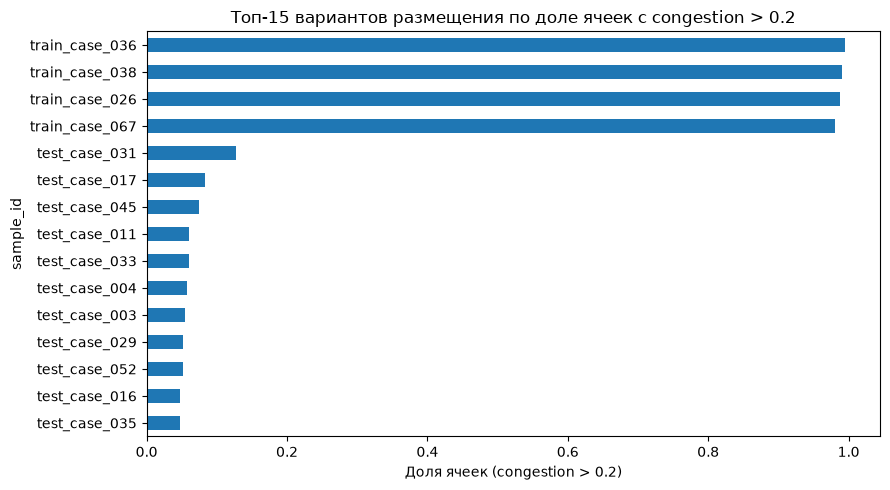

In [62]:
query = '''
    SELECT 
        s.sample_id,
        s.design,
        s.frequency,
        COUNT(g.cell_id) AS total_cells,
        SUM(CASE WHEN g.congestion > 0.2 THEN 1 ELSE 0 END) AS high_congestion_cells,
        1.0 * SUM(CASE WHEN g.congestion > 0.2 THEN 1 ELSE 0 END) / COUNT(g.cell_id) AS congestion_ratio
    FROM grid_cells AS g
    JOIN samples AS s
        ON s.sample_id = g.sample_id
    GROUP BY s.sample_id, s.design, s.frequency
    ORDER BY congestion_ratio DESC
    LIMIT 15
'''

df_ranked = pd.read_sql_query(query, connection)
display(df_ranked)

# Построение горизонтальной столбчатой диаграммы
ax = df_ranked.plot(
    x='sample_id',
    y='congestion_ratio',
    kind='barh',
    figsize=(9, 5),
    legend=False,
    title='Топ-15 вариантов размещения по доле ячеек с congestion > 0.2'
)
ax.set_xlabel('Доля ячеек (congestion > 0.2)')
ax.set_ylabel('sample_id')
plt.gca().invert_yaxis()  # наибольшие значения сверху
plt.tight_layout()
plt.show()


### Завершение работы

Соединение с базой данных нужно закрывать после окончания работы. Это освобождает ресурсы и файловые дескрипторы.

Запускайте следующий блок кода после выполнения всех SQL-заданий.


In [63]:
connection.close()


## Контрольные вопросы

1. Что представляет собой объект `DataFrame` в библиотеке Pandas и чем он отличается от `Series`?
2. В чём различие между методами `.loc[]` и `.iloc[]` при выборе строк и столбцов?
3. Что такое булева маска в Pandas и как с её помощью отфильтровать строки по нескольким условиям?
4. Для чего используется метод `.groupby()` и какую роль выполняет `.agg()` после группировки?
5. Чем среднее арифметическое отличается от медианы и в каких случаях медиана может быть более информативной?
6. Что показывает 95-й процентиль `congestion` и как его вычислить средствами Pandas?
7. Для чего при построении диаграммы рассеяния большой таблицы используется случайная подвыборка и параметр `alpha`?
8. Что характеризуют признаки `rudy`, `rudy_pin` и `congestion` в контексте физического проектирования интегральных схем?
9. В чём назначение полей `PRIMARY KEY` и `FOREIGN KEY` в реляционной базе данных?
10. Чем отличаются методы курсора SQLite `fetchone()`, `fetchmany()` и `fetchall()`?
11. В чём принципиальная разница между условиями `WHERE` и `HAVING` в SQL-запросе?
12. Для чего используется `JOIN` и по какому полю в данной лабораторной работе соединяются таблицы `samples` и `grid_cells`?
13. Что такое подзапрос в SQL и зачем он используется в задании со сравнением среднего `congestion` группы с общим средним?
14. Как с помощью конструкции `SUM(CASE WHEN ... THEN 1 ELSE 0 END)` подсчитать количество строк, удовлетворяющих условию?
